<a href="https://colab.research.google.com/github/MashrufAhmed-470/machine-learning/blob/main/DRAFT_ML_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
url = 'https://www.kaggle.com/datasets/susuwatari/epa-vehicle-dataset-19802021'

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, mean_squared_error, classification_report, confusion_matrix

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("susuwatari/epa-vehicle-dataset-19802021")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/susuwatari/epa-vehicle-dataset-19802021/versions/1


In [ ]:
import os

# List all files in the current working directory
print("Files in current directory:", os.listdir())

Files in current directory: ['.config', 'vehicles.csv', 'sample_data']


1. Data Exploration

In [ ]:
import pandas as pd

# Load the file
data = pd.read_csv("vehicles.csv")

# Display basic info about the dataset
print("Dataset shape:", data.shape)
print("Column names:", data.columns)
print("First few rows:\n", data.head())
print("Missing values:\n", data.isnull().sum())
print("Data types:\n", data.dtypes)
print(data.info())

Dataset shape: (42230, 83)
Column names: Index(['barrels08', 'barrelsA08', 'charge120', 'charge240', 'city08',
       'city08U', 'cityA08', 'cityA08U', 'cityCD', 'cityE', 'cityUF', 'co2',
       'co2A', 'co2TailpipeAGpm', 'co2TailpipeGpm', 'comb08', 'comb08U',
       'combA08', 'combA08U', 'combE', 'combinedCD', 'combinedUF', 'cylinders',
       'displ', 'drive', 'engId', 'eng_dscr', 'feScore', 'fuelCost08',
       'fuelCostA08', 'fuelType', 'fuelType1', 'ghgScore', 'ghgScoreA',
       'highway08', 'highway08U', 'highwayA08', 'highwayA08U', 'highwayCD',
       'highwayE', 'highwayUF', 'hlv', 'hpv', 'id', 'lv2', 'lv4', 'make',
       'model', 'mpgData', 'phevBlended', 'pv2', 'pv4', 'range', 'rangeCity',
       'rangeCityA', 'rangeHwy', 'rangeHwyA', 'trany', 'UCity', 'UCityA',
       'UHighway', 'UHighwayA', 'VClass', 'year', 'youSaveSpend', 'guzzler',
       'trans_dscr', 'tCharger', 'sCharger', 'atvType', 'fuelType2', 'rangeA',
       'evMotor', 'mfrCode', 'c240Dscr', 'charge240b', 'c2

<ipython-input-6-e0e7155e78f5>:4: DtypeWarning: Columns (70,71,72,73,74,76,79) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("vehicles.csv")


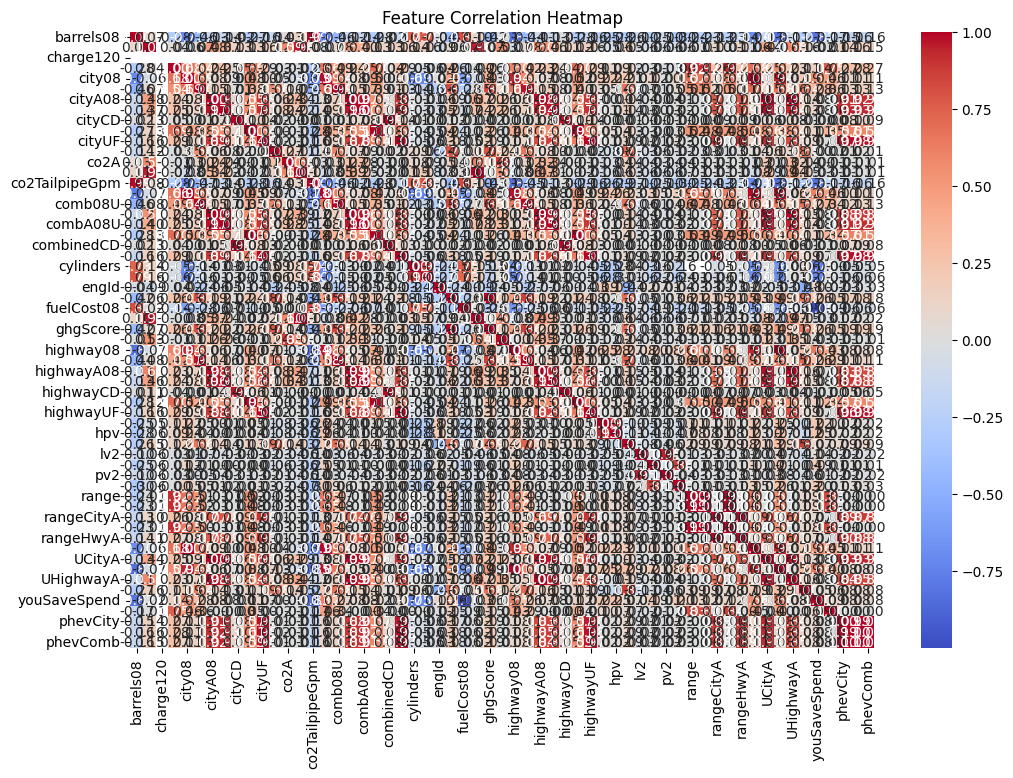

In [ ]:
# Select numerical columns for correlation
numerical_data = data.select_dtypes(include=[np.number])

# Check if numerical columns exist
if numerical_data.shape[1] == 0:
    print("No numerical columns available for correlation.")
else:
    # Visualize correlations between numerical features
    plt.figure(figsize=(12, 8))
    sns.heatmap(numerical_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title("Feature Correlation Heatmap")
    plt.show()


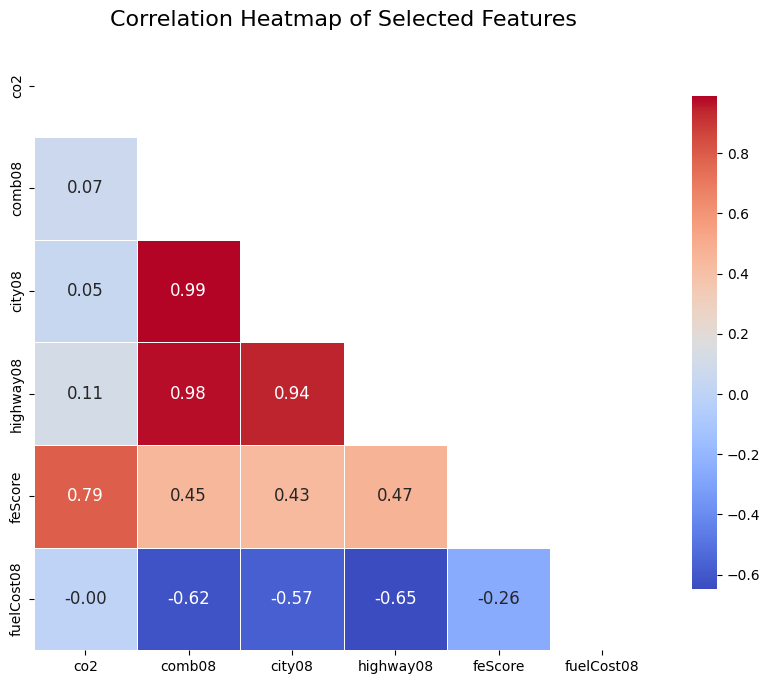

In [ ]:
# Select a subset of numerical features for clarity
selected_columns = ['co2', 'comb08', 'city08', 'highway08', 'feScore', 'fuelCost08']

# Extract the numerical data from selected columns
correlation_data = data[selected_columns]

# Compute the correlation matrix
correlation_matrix = correlation_data.corr()

# Set up the figure and axis for the plot
plt.figure(figsize=(10, 8))

# Mask the upper triangle of the correlation matrix (to avoid redundancy)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Generate the heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', mask=mask,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, annot_kws={"size": 12})

# Title and show the plot
plt.title("Correlation Heatmap of Selected Features", fontsize=16)
plt.show()

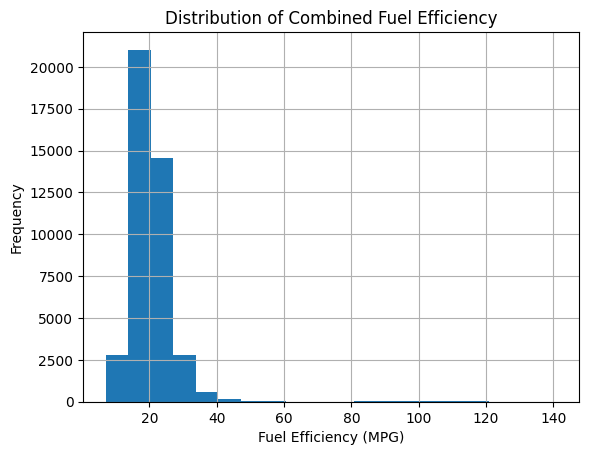

In [ ]:
# Visualize distribution of 'comb08' (combined fuel efficiency)
data['comb08'].hist(bins=20)
plt.title("Distribution of Combined Fuel Efficiency")
plt.xlabel("Fuel Efficiency (MPG)")
plt.ylabel("Frequency")
plt.show()


2. Principal Component Analysis (PCA)

In [ ]:
# Drop non-numerical columns
numeric_data = data.select_dtypes(include=np.number).dropna()

# Apply PCA to reduce to 96% variance
pca = PCA(n_components=0.96)
principal_components = pca.fit_transform(numeric_data)

# Display results
print(f"Number of components to retain 96% variance: {pca.n_components_}")
print("Explained Variance Ratio:", pca.explained_variance_ratio_)


Number of components to retain 96% variance: 2
Explained Variance Ratio: [0.75008126 0.23634045]


3. Machine Learning Model Example
a. Random Forest Classification (Example target: 'phevBlended')

In [ ]:
# Example: Predict 'phevBlended' (whether the vehicle is blended with electric)
X = data.drop(columns=['phevBlended'])  # Features
y = data['phevBlended']  # Target

# Encode categorical variables
X = pd.get_dummies(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train a Random Forest Classifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# Predict and evaluate
y_pred_rf = rf.predict(X_test)
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Classification Report:
              precision    recall  f1-score   support

       False       1.00      1.00      1.00     12633
        True       0.97      1.00      0.99        36

    accuracy                           1.00     12669
   macro avg       0.99      1.00      0.99     12669
weighted avg       1.00      1.00      1.00     12669



b. Random Forest Regression (Example target: 'co2')

In [ ]:
# Example: Predict 'co2' emissions
X_reg = data.drop(columns=['co2'])  # Features
y_reg = data['co2']  # Target

# Encode categorical variables
X_reg = pd.get_dummies(X_reg)

# Train-test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

# Train a Random Forest Regressor
# Reduce number of trees and max depth for faster execution
rfr = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)  # Fewer trees and smaller depth
rfr.fit(X_train_reg, y_train_reg)

# Predict and evaluate
y_pred_rfr = rfr.predict(X_test_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_rfr))
print(f"Random Forest Regression RMSE: {rmse}")

Random Forest Regression RMSE: 1.38534826597604


In [ ]:
# ALTERNATIVE
# Example: Predict 'co2' emissions
X_reg = data.drop(columns=['co2'])  # Features
y_reg = data['co2']  # Target

# Encode categorical variables
X_reg = pd.get_dummies(X_reg)

# Train-test split
from sklearn.model_selection import train_test_split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

# Train the model
from sklearn.ensemble import RandomForestRegressor
rfr = RandomForestRegressor(random_state=42)
rfr.fit(X_train_reg, y_train_reg)

# Predict and evaluate
from sklearn.metrics import mean_squared_error
y_pred_rfr = rfr.predict(X_test_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_rfr))
print(f"Random Forest Regression RMSE: {rmse}")


4. Feature Importance for Random Forest


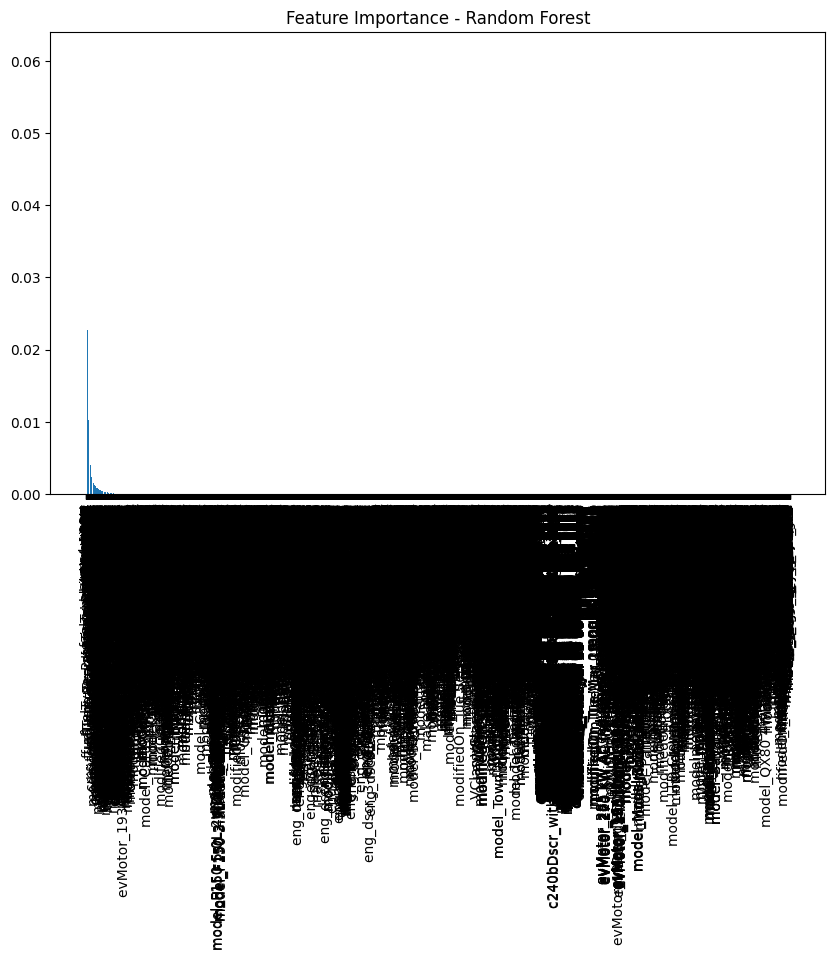

In [ ]:
# Plot feature importance
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.bar(range(X.shape[1]), importances[indices])
plt.xticks(range(X.shape[1]), X.columns[indices], rotation=90)
plt.title("Feature Importance - Random Forest")
plt.show()


5. Iterative Improvements (Hyperparameter Tuning)

In [ ]:
# Hyperparameter tuning example for Random Forest
rf_tuned = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
rf_tuned.fit(X_train, y_train)
scores = cross_val_score(rf_tuned, X, y, cv=5)
print("Cross-Validation Accuracy:", scores.mean())


Cross-Validation Accuracy: 0.9999526403031019


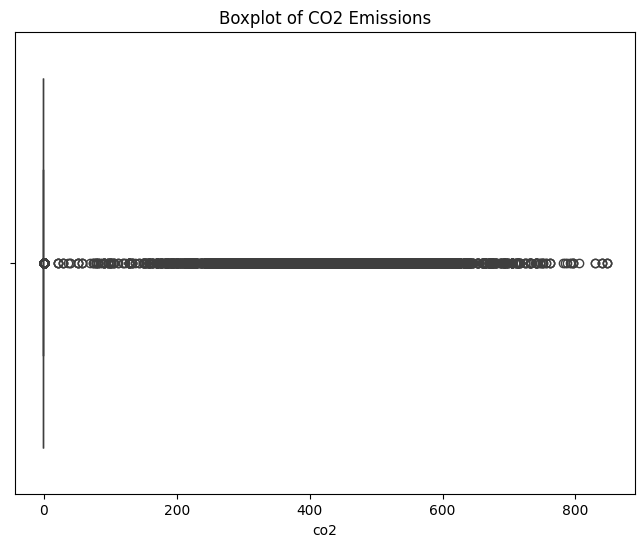

In [ ]:
# Boxplot of 'co2' emissions (you can replace this with any numerical feature)
plt.figure(figsize=(8, 6))
sns.boxplot(x=data['co2'])
plt.title("Boxplot of CO2 Emissions")
plt.show()


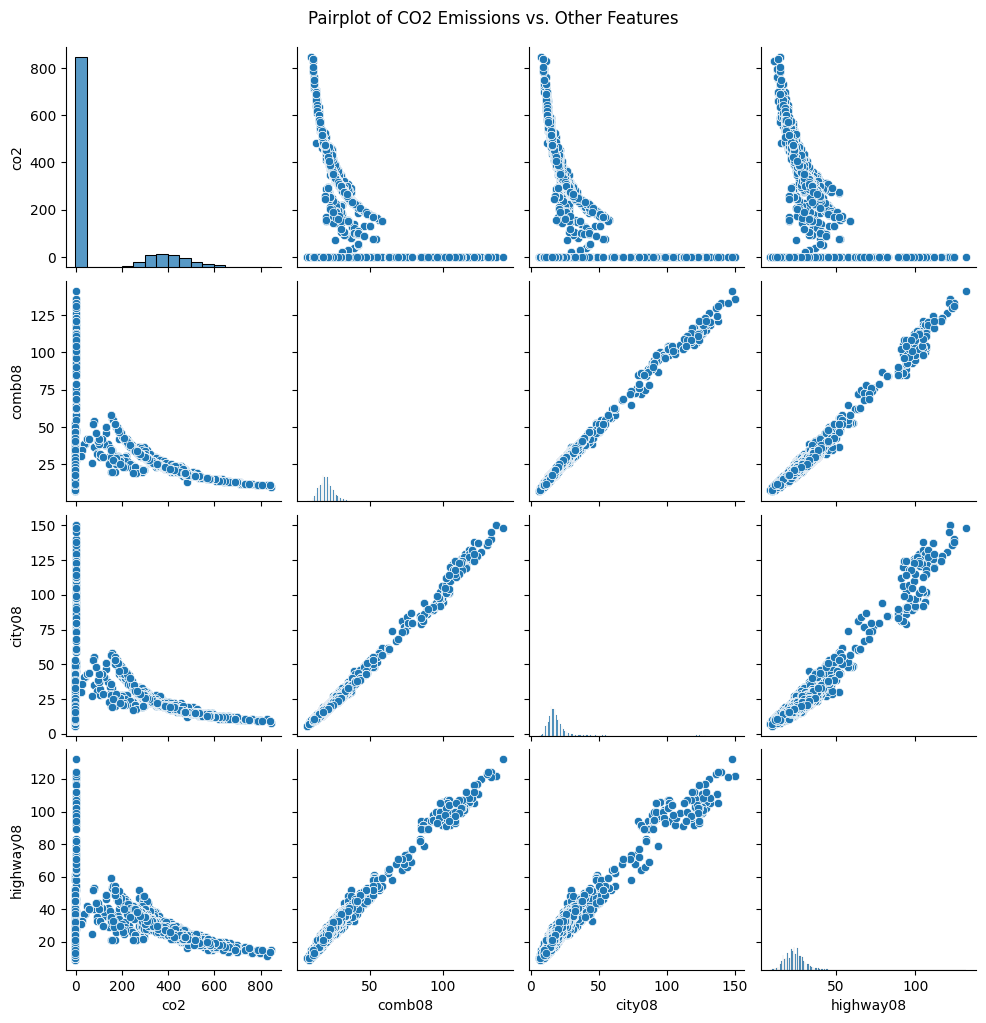

In [ ]:
# Plot pairplot for selected columns (replace with your desired columns)
sns.pairplot(data[['co2', 'comb08', 'city08', 'highway08']])
plt.suptitle("Pairplot of CO2 Emissions vs. Other Features", y=1.02)
plt.show()


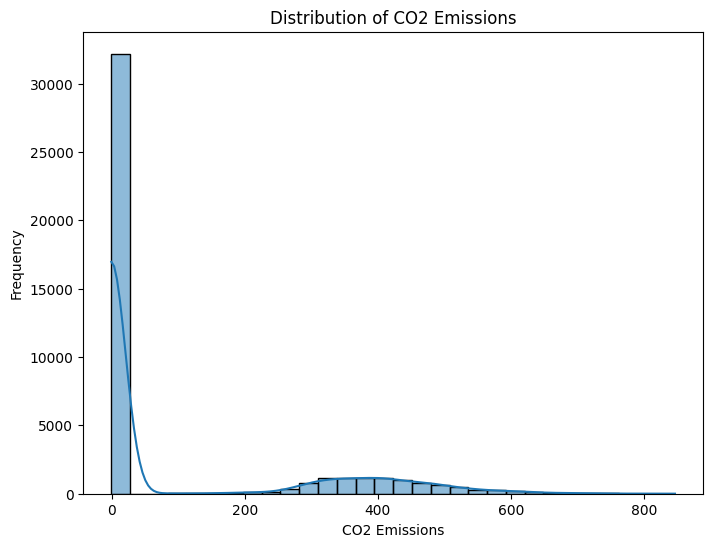

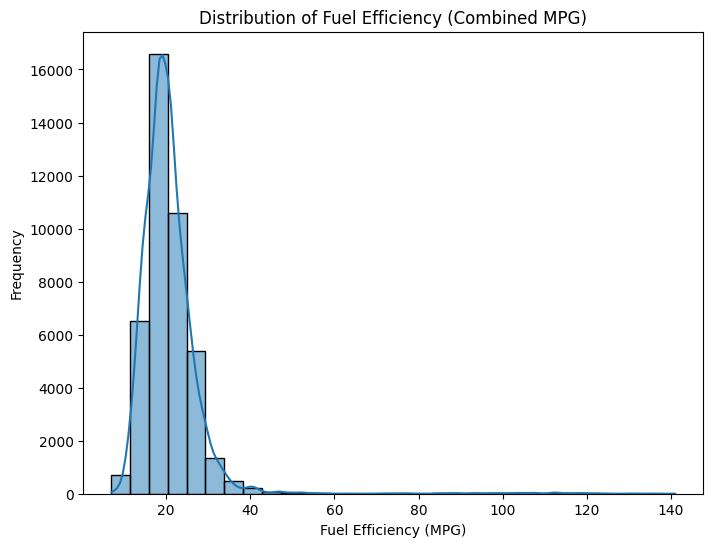

In [ ]:
# Distribution of CO2 emissions
plt.figure(figsize=(8, 6))
sns.histplot(data['co2'], kde=True, bins=30)
plt.title("Distribution of CO2 Emissions")
plt.xlabel("CO2 Emissions")
plt.ylabel("Frequency")
plt.show()

# Fuel efficiency distribution (replace with 'comb08' or 'city08')
plt.figure(figsize=(8, 6))
sns.histplot(data['comb08'], kde=True, bins=30)
plt.title("Distribution of Fuel Efficiency (Combined MPG)")
plt.xlabel("Fuel Efficiency (MPG)")
plt.ylabel("Frequency")
plt.show()


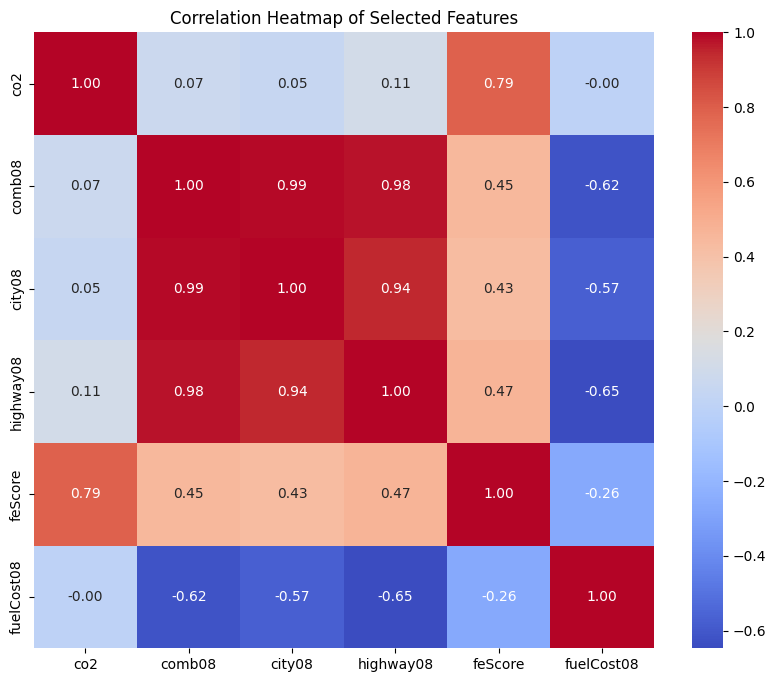

In [ ]:
# Select specific features for correlation plot (you can replace with your chosen features)
selected_columns = ['co2', 'comb08', 'city08', 'highway08', 'feScore', 'fuelCost08']
correlation_data = data[selected_columns]

# Correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Selected Features")
plt.show()


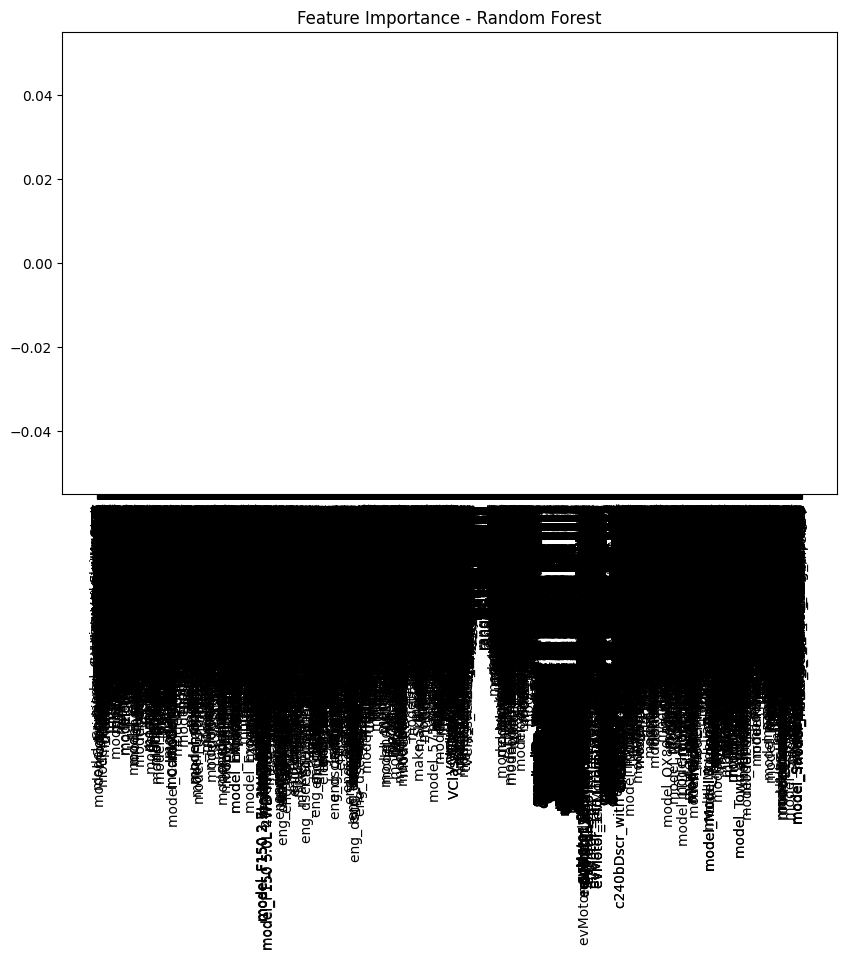

In [ ]:
# Feature Importance for Random Forest Model (assuming you've already trained a model like rfr)
importances = rfr.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.bar(range(X_train_reg.shape[1]), importances[indices])
plt.xticks(range(X_train_reg.shape[1]), X.columns[indices], rotation=90)
plt.title("Feature Importance - Random Forest")
plt.show()


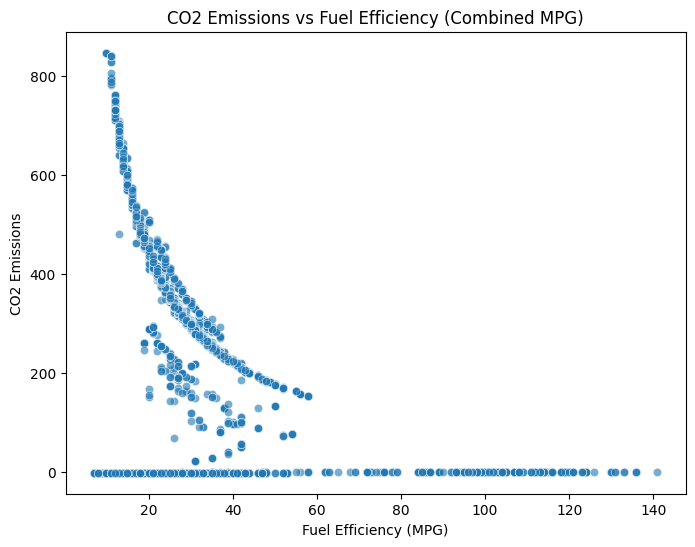

In [ ]:
# Scatter plot to show relationship between 'co2' and some other features
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data['comb08'], y=data['co2'], alpha=0.6)
plt.title("CO2 Emissions vs Fuel Efficiency (Combined MPG)")
plt.xlabel("Fuel Efficiency (MPG)")
plt.ylabel("CO2 Emissions")
plt.show()


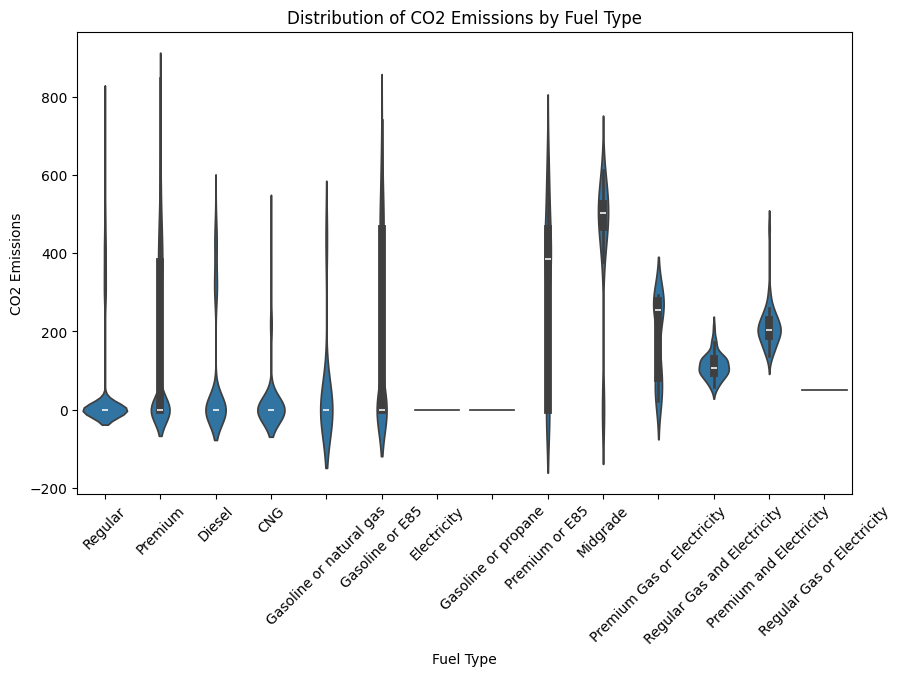

In [ ]:
# Violin plot of CO2 emissions by fuel type
plt.figure(figsize=(10, 6))
sns.violinplot(x=data['fuelType'], y=data['co2'])
plt.title("Distribution of CO2 Emissions by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("CO2 Emissions")
plt.xticks(rotation=45)
plt.show()


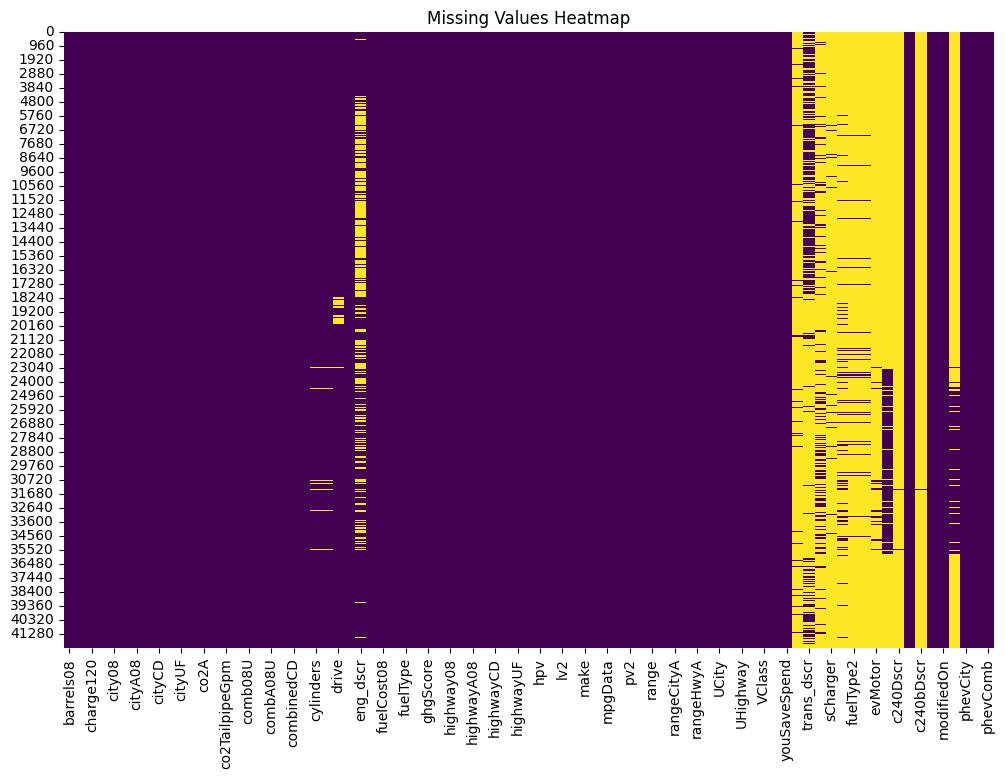

In [ ]:
# Visualize missing values as a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()
